In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import torch
from tqdm.notebook import tqdm

# Display each figure when all its panels are ready
plt.ioff()

# Define standard colors for REAL and FAKE for consistency across plots
colors = {0: "#d95f02", 1: "#1b9e77"}  # 0: FAKE (Orange), 1: REAL (Green)

In [2]:
# 1. Define and build the DataFrame (df)
DATASET_DIR = Path("/home/gabor-levai/Downloads/AI_VIS/archive (3)")
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
records = []

print(f"Scanning directory: {DATASET_DIR}")

for filepath in DATASET_DIR.rglob("*"):
    if filepath.is_file() and filepath.suffix.lower() in valid_extensions:
        parts_lower = [p.lower() for p in filepath.parts]
        
        # Categorize label based on folder structure or filename
        if any("real" in p for p in parts_lower):
            label = "Real"
        elif any("fake" in p for p in parts_lower):
            label = "Fake"
        else:
            label = "Unknown"
        
        records.append({
            "filepath": str(filepath),
            "label": label
        })

df = pd.DataFrame(records)
print(f"Scanned {len(df)} total images.")

# 2. Filter out "Unknown" items; only keep Real and Fake
df_filtered = df[df["label"].isin(["Real", "Fake"])].copy()

# 3. Split into Training (80%) and Testing (20%)
train_df, test_df = train_test_split(
    df_filtered, test_size=0.2, random_state=42, stratify=df_filtered["label"]
)

Scanning directory: /home/gabor-levai/Downloads/AI_VIS/archive (3)
Scanned 2041 total images.


In [3]:
# 4. Define the PyTorch Dataset
class DeepfakeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.label_map = {"Real": 1, "Fake": 0}
        
    def __len__(self):
        return len(self.dataframe)
    
    def __getitem__(self, idx):
        img_path = self.dataframe.loc[idx, "filepath"]
        label_str = self.dataframe.loc[idx, "label"]
        
        image = Image.open(img_path).convert('RGB')
        label = self.label_map[label_str]
        
        if self.transform:
            image = self.transform(image)
            
        return image, torch.tensor(label, dtype=torch.float32), img_path

# 5. Define Transforms
# Note: For statistical analysis of brightness/contrast/etc., we do NOT want ImageNet normalization. 
# We just want to resize them to a standard size and convert to a tensor [0.0, 1.0].
analysis_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor() 
])

train_dataset = DeepfakeDataset(train_df, transform=analysis_transform)
# Using a larger batch size for faster statistics extraction
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=4) 

print(f"Training samples for analysis: {len(train_dataset)}")

Training samples for analysis: 1632


In [4]:
# This is the calculation used for the four saved properties.
# Modified to accept PyTorch Tensors which are already in [0.0, 1.0]
def image_properties(rgb_images):
    # rgb_images shape: (Batch, Channels, Height, Width)
    # Combine the colour channels into one brightness image.
    luma = np.einsum("nchw,c->nhw", rgb_images, np.array([0.299, 0.587, 0.114], np.float32))
    
    # A larger gap between colour channels means stronger saturation.
    highest, lowest = rgb_images.max(axis=1), rgb_images.min(axis=1)
    saturation = np.divide(highest-lowest, highest, out=np.zeros_like(highest), where=highest > 0)
    
    # Compare each interior pixel with its neighbours to measure fine detail.
    laplacian = (luma[:, :-2, 1:-1] + luma[:, 2:, 1:-1]
                 + luma[:, 1:-1, :-2] + luma[:, 1:-1, 2:] - 4*luma[:, 1:-1, 1:-1])
    
    # Keep one row per image: Brightness, Contrast, Saturation, Sharpness
    return np.column_stack([luma.mean((1, 2)), luma.std((1, 2)),
                            saturation.mean((1, 2)), laplacian.var((1, 2))])

# Extract statistics across the training set without running out of memory
all_stats = []
all_labels = []

# To compute mean images
real_sum = np.zeros((3, 224, 224), dtype=np.float64)
fake_sum = np.zeros((3, 224, 224), dtype=np.float64)
real_count = 0
fake_count = 0

preview_images = []
preview_labels = []

print("Extracting statistics and computing mean images...")
for images, labels, _ in tqdm(train_loader):
    images_np = images.numpy()
    labels_np = labels.numpy()
    
    # Store first 12 images for preview
    for i in range(len(images_np)):
        if len(preview_images) < 12:
            preview_images.append(images_np[i])
            preview_labels.append(labels_np[i])
            
        # Accumulate sums for mean images
        if labels_np[i] == 1:
            real_sum += images_np[i]
            real_count += 1
        else:
            fake_sum += images_np[i]
            fake_count += 1
            
    # Compute and store batch stats
    batch_stats = image_properties(images_np)
    all_stats.append(batch_stats)
    all_labels.append(labels_np)

# Concatenate all gathered batches
stats = np.vstack(all_stats)
labels = np.concatenate(all_labels)
preview_images = np.array(preview_images)
preview_labels = np.array(preview_labels)

mean_real_image = (real_sum / real_count) if real_count > 0 else np.zeros_like(real_sum)
mean_fake_image = (fake_sum / fake_count) if fake_count > 0 else np.zeros_like(fake_sum)

print(f"Extraction complete. FAKE: {(labels == 0).sum():,} · REAL: {(labels == 1).sum():,}")

Extracting statistics and computing mean images...


  0%|          | 0/26 [00:00<?, ?it/s]

Extraction complete. FAKE: 768 · REAL: 864


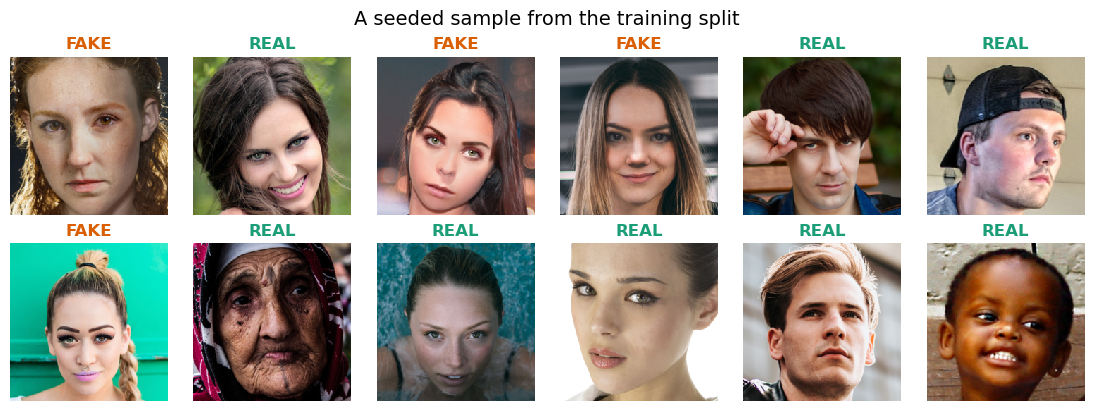

In [5]:
# Show the fixed sample of 12 images with the correct label
fig, axes = plt.subplots(2, 6, figsize=(11, 4), layout="constrained")
for ax, image, label in zip(axes.flat, preview_images, preview_labels):
    # Matplotlib needs height × width × colour, so move the colour axis to the end.
    ax.imshow(image.transpose(1, 2, 0), interpolation="nearest")
    ax.set_title("FAKE" if label == 0 else "REAL", color=colors[int(label)], fontweight='bold')
    ax.axis("off")
fig.suptitle("A seeded sample from the training split", fontsize=14)
plt.show()

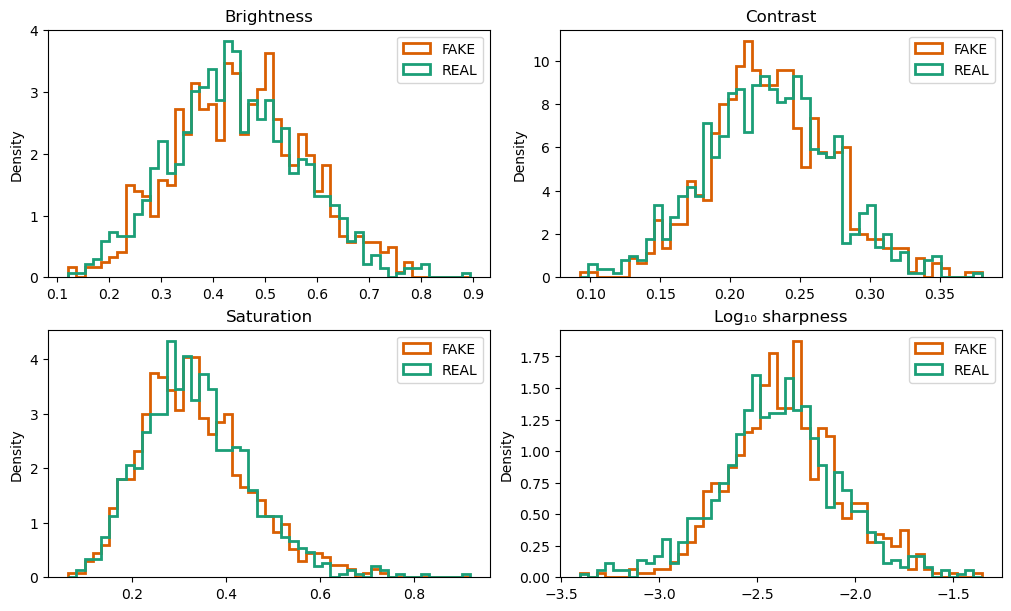

In [6]:
# Normalize each histogram because the labels have slightly different counts.
values = stats.copy()
# Sharpness has a long tail; a log scale makes the distributions easier to compare.
values[:, 3] = np.log10(values[:, 3] + 1e-8)
titles = ["Brightness", "Contrast", "Saturation", "Log₁₀ sharpness"]

fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
for column, ax in enumerate(axes.flat):
    # Give REAL and FAKE the same bin edges within this panel.
    bins = np.linspace(values[:, column].min(), values[:, column].max(), 50)
    for label, name in [(0, "FAKE"), (1, "REAL")]:
        # Density makes the areas comparable even though the label counts differ.
        ax.hist(values[labels == label, column], bins=bins, density=True,
                histtype="step", lw=2, color=colors[label], label=name)
    ax.set(title=titles[column], ylabel="Density")
    ax.legend()
plt.show()

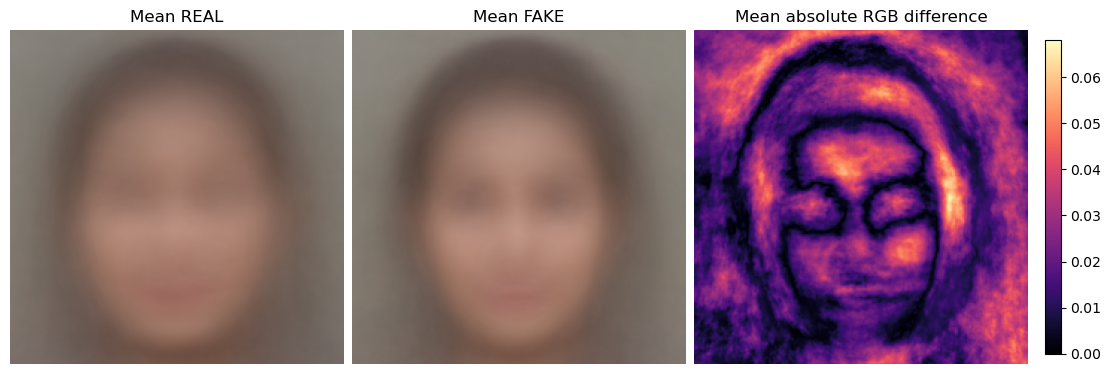

In [7]:
# Compute the difference between the mean real and mean fake images
# Average the absolute colour-channel gaps into one number per pixel.
difference = np.abs(mean_fake_image - mean_real_image).mean(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(11, 4), layout="constrained")

# Note: matplotlib expects shapes as (H, W, C) so we transpose
axes[0].imshow(mean_real_image.transpose(1, 2, 0))
axes[1].imshow(mean_fake_image.transpose(1, 2, 0))

# Brighter areas in this panel mean a larger gap between the two mean images.
heat = axes[2].imshow(difference, cmap="magma", vmin=0)

for ax, title in zip(axes, ["Mean REAL", "Mean FAKE", "Mean absolute RGB difference"]):
    ax.set_title(title)
    ax.axis("off")
    
fig.colorbar(heat, ax=axes[2], shrink=0.8)
plt.show()